# Lab 2: Decision Trees — ID3, CART and C4.5
**Dataset:** Titanic passengers (real-life data) — predict who **survived**
**Goal:** Build all three algorithms from scratch, compare them, and understand *why* we move from one to the next.

## 1. Roadmap: why ID3 → CART → C4.5?
| Step | Algorithm | Split measure | Split type | What it fixes / what is still missing |
|---|---|---|---|---|
| 1 | **ID3** | Entropy → Information Gain | Multiway | Simplest starting point. But: categorical data only, no missing values, no pruning (overfits), **biased towards attributes with many values** |
| 2 | **CART** | Gini Index | Binary (yes/no) | Handles **numeric** attributes with thresholds, binary splits reduce many-value bias, supports **pruning**; same tree also works for regression |
| 3 | **C4.5** | Entropy → **Gain Ratio** | Multiway (cat) / Binary (num) | Directly fixes ID3's bias (gain ratio), handles numeric + **missing values**, and has built-in **pruning** |

**One-line story:** ID3 is the idea → CART makes it practical (numeric, binary, pruning) → C4.5 repairs ID3's own weaknesses while keeping entropy-style readable rules.

*Note: historically CART (1984) was developed independently of ID3 (1986); C4.5 (1993) is ID3's direct successor.*

## 2. Dataset: Titanic
- 891 passengers, target = `survived` (1 = survived, 0 = died)
- Real-life mix of data types, which is exactly what makes the three algorithms behave differently:

| Attribute | Type | Meaning |
|---|---|---|
| pclass | ordinal | Ticket class (1, 2, 3) |
| sex | categorical | male / female |
| age | numeric (has missing values) | Age in years |
| sibsp | numeric | Siblings / spouses aboard |
| parch | numeric | Parents / children aboard |
| fare | numeric | Ticket price |
| embarked | categorical (has missing values) | Port: C, Q, S |

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.model_selection import train_test_split

raw = pd.read_csv("data/titanic.csv")
cols = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
y = raw["survived"].values

print("Shape:", raw.shape)
print("Survived counts:", dict(Counter(y.tolist())))
print("\nMissing values:")
print(raw[cols].isnull().sum()[lambda s: s > 0])
raw[cols + ["survived"]].head()

Shape: (891, 15)
Survived counts: {0: 549, 1: 342}

Missing values:
age         177
embarked      2
dtype: int64


,pclass,sex,age,sibsp,parch,fare,embarked,survived
0,3,male,22.0,1,0,7.2500,S,0
1,1,female,38.0,1,0,71.2833,C,1
2,3,female,26.0,0,0,7.9250,S,1
3,1,female,35.0,1,0,53.1000,S,1
4,3,male,35.0,0,0,8.0500,S,0


In [2]:
print("Survival rate by sex:")
print(raw.groupby("sex")["survived"].mean().round(3), "\n")
print("Survival rate by class:")
print(raw.groupby("pclass")["survived"].mean().round(3))

Survival rate by sex:
sex
female    0.742
male      0.189
Name: survived, dtype: float64 

Survival rate by class:
pclass
1    0.630
2    0.473
3    0.242
Name: survived, dtype: float64


## 3. Core Concepts (read before the code)
Let a node hold a set **S** with classes *survived* / *died*, and let p = fraction of survived.

| Concept | Formula | Meaning |
|---|---|---|
| **Entropy** | H(S) = − Σ pᵢ log₂ pᵢ | Disorder. 0 = pure, 1 = 50/50 (two classes) |
| **Information Gain** (ID3) | IG(S,A) = H(S) − Σ (\|Sᵥ\|/\|S\|) · H(Sᵥ) | Entropy drop after splitting on A |
| **Gini Index** (CART) | G(S) = 1 − Σ pᵢ² | Impurity. 0 = pure, 0.5 = 50/50 (two classes) |
| **Gini Decrease** | G(S) − Σ (\|Sᵥ\|/\|S\|) · G(Sᵥ) | Impurity drop after splitting |
| **Split Information** | SI(S,A) = − Σ (\|Sᵥ\|/\|S\|) log₂ (\|Sᵥ\|/\|S\|) | Penalty: large for attributes with many values |
| **Gain Ratio** (C4.5) | GR = IG / SI | Information gain, corrected for many-valued attributes |

**Greedy rule (all three):** at each node pick the best split, divide the data, repeat on each child until the node is pure or a stopping rule fires.

In [3]:
# One common train/test split for all algorithms (70/30, same passengers for everyone)
train_idx, test_idx = train_test_split(np.arange(len(raw)), test_size=0.3, stratify=y, random_state=42)
ytr, yte = y[train_idx], y[test_idx]

def make_views(tr_idx):
    """Build the three data views. Statistics (median, mode, fare bins) come ONLY from the training rows."""
    age_median = raw.loc[tr_idx, "age"].median()
    emb_mode = raw.loc[tr_idx, "embarked"].mode()[0]
    fare_edges = np.quantile(raw.loc[tr_idx, "fare"], [0, .25, .5, .75, 1]).astype(float)
    fare_edges[0], fare_edges[-1] = -np.inf, np.inf

    # View 1 - ID3 needs ONLY categorical data, no missing -> bin numbers, 'unknown' category
    v_id3 = pd.DataFrame({
        "pclass": raw.pclass.astype(str),
        "sex": raw.sex,
        "age": pd.cut(raw.age, [0, 12, 18, 35, 60, 120],
                      labels=["child", "teen", "young_adult", "adult", "senior"]).astype(object).fillna("unknown"),
        "sibsp": raw.sibsp.clip(upper=3).astype(str),
        "parch": raw.parch.clip(upper=3).astype(str),
        "fare": pd.cut(raw.fare, fare_edges, labels=["low", "mid", "high", "very_high"]).astype(str),
        "embarked": raw.embarked.fillna("unknown"),
    })
    # View 2 - CART handles numbers directly, but missing values are filled (median / mode)
    v_cart = raw[cols].copy()
    v_cart["age"] = v_cart["age"].fillna(age_median)
    v_cart["embarked"] = v_cart["embarked"].fillna(emb_mode)
    # View 3 - C4.5 handles numbers AND missing values (NaN kept as it is)
    v_c45 = raw[cols].copy()
    return v_id3, v_cart, v_c45

X_id3, X_cart, X_c45 = make_views(train_idx)

def split(X):
    return X.iloc[train_idx].reset_index(drop=True), X.iloc[test_idx].reset_index(drop=True)

Xtr_id3, Xte_id3 = split(X_id3)
Xtr_cart, Xte_cart = split(X_cart)
Xtr_c45, Xte_c45 = split(X_c45)

print("Train:", len(ytr), "| Test:", len(yte))
print("Baseline (always predict 'died'):", round(1 - yte.mean(), 4))
Xtr_id3.head()

Train: 623 | Test: 268
Baseline (always predict 'died'): 0.6157


,pclass,sex,age,sibsp,parch,fare,embarked
0,1,male,young_adult,1,0,very_high,S
1,3,male,unknown,0,0,mid,S
2,3,female,unknown,0,0,low,Q
3,1,male,unknown,0,0,low,S
4,3,male,young_adult,1,0,high,S


**Why three different views of the same data?** Each algorithm has different abilities:
- **ID3** → only categories, no missing values, so we bin `age`, `fare` and add an `unknown` category.
- **CART** → numbers are fine, but we fill missing values with median / mode.
- **C4.5** → numbers and missing values are both handled inside the algorithm.

## 4. Manual Calculation at the Root (same steps you do on paper)
We check the attribute **sex** at the root of the training data and compute all three measures.

In [4]:
def entropy(y):
    n = len(y)
    if n == 0:
        return 0.0
    return -sum((c / n) * math.log2(c / n) for c in Counter(np.asarray(y).tolist()).values())

def gini(y):
    n = len(y)
    if n == 0:
        return 0.0
    return 1 - sum((c / n) ** 2 for c in Counter(np.asarray(y).tolist()).values())

def manual_root(X, y, feat):
    n, p = len(y), int(y.sum())
    H, G = entropy(y), gini(y)
    print(f"Root: {n} passengers -> survived = {p}, died = {n - p}")
    print(f"Entropy(root) = {H:.4f}   |   Gini(root) = {G:.4f}\n")
    wH = wG = SI = 0.0
    for v in sorted(X[feat].unique()):
        m = (X[feat] == v).values
        nv, pv = int(m.sum()), int(y[m].sum())
        h, g = entropy(y[m]), gini(y[m])
        print(f"  {feat} = {v:7s}: n = {nv:3d} (survived {pv:3d}, died {nv - pv:3d})  entropy = {h:.4f}  gini = {g:.4f}")
        wH += nv / n * h; wG += nv / n * g; SI -= nv / n * math.log2(nv / n)
    print(f"\nWeighted entropy after split = {wH:.4f}")
    print(f"Information Gain  (ID3)  = {H:.4f} - {wH:.4f} = {H - wH:.4f}")
    print(f"Gini Decrease     (CART) = {G:.4f} - {wG:.4f} = {G - wG:.4f}")
    print(f"Split Information        = {SI:.4f}")
    print(f"Gain Ratio        (C4.5) = {H - wH:.4f} / {SI:.4f} = {(H - wH) / SI:.4f}")

manual_root(Xtr_id3, ytr, "sex")

Root: 623 passengers -> survived = 239, died = 384
Entropy(root) = 0.9606   |   Gini(root) = 0.4729

  sex = female : n = 217 (survived 163, died  54)  entropy = 0.8094  gini = 0.3738
  sex = male   : n = 406 (survived  76, died 330)  entropy = 0.6956  gini = 0.3043

Weighted entropy after split = 0.7352
Information Gain  (ID3)  = 0.9606 - 0.7352 = 0.2253
Gini Decrease     (CART) = 0.4729 - 0.3285 = 0.1444
Split Information        = 0.9326
Gain Ratio        (C4.5) = 0.2253 / 0.9326 = 0.2416


# Part A — ID3
**Idea:** at every node choose the categorical attribute with the **highest Information Gain**, create **one branch per value**, and never reuse an attribute on the same path. Stop when the node is pure or no attributes are left.

In [5]:
# ---------- Shared tree building blocks ----------
class Node:
    def __init__(self, y):
        self.counts = Counter(np.asarray(y).tolist())
        self.n = len(y)
        self.label = self.counts.most_common(1)[0][0]      # majority class
        self.feature = self.kind = self.threshold = self.majority_branch = None
        self.children = {}
    @property
    def is_leaf(self):
        return self.feature is None

def predict_row(node, row):
    while not node.is_leaf:
        v = row[node.feature]
        if node.kind == "cat":                              # multiway split
            key = node.majority_branch if pd.isna(v) else v
            if key not in node.children:                    # unseen value -> majority class of this node
                return node.label
            node = node.children[key]
        elif node.kind == "num":                            # threshold split
            key = node.majority_branch if pd.isna(v) else ("<=" if v <= node.threshold else ">")
            node = node.children[key]
        else:                                               # "bin": category == value ?
            node = node.children["yes" if v == node.threshold else "no"]
    return node.label

def predict(node, X):
    return np.array([predict_row(node, r) for _, r in X.iterrows()])

def tree_stats(node, d=0):
    if node.is_leaf:
        return 1, 1, d
    kids = [tree_stats(c, d + 1) for c in node.children.values()]
    return 1 + sum(k[0] for k in kids), sum(k[1] for k in kids), max(k[2] for k in kids)

def show(node, indent="", max_depth=3, depth=0):
    for key, child in node.children.items():
        if node.kind == "cat":
            cond = f"{node.feature} = {key}"
        elif node.kind == "num":
            cond = f"{node.feature} {key} {node.threshold:.2f}"
        else:
            cond = f"{node.feature} {'==' if key == 'yes' else '!='} {node.threshold}"
        print(f"{indent}{cond}")
        if child.is_leaf or depth + 1 >= max_depth:
            tag = "" if child.is_leaf else "  [subtree hidden]"
            print(f"{indent}    -> {'SURVIVED' if child.label == 1 else 'DIED'}  (n={child.n}, {dict(child.counts)}){tag}")
        else:
            show(child, indent + "    ", max_depth, depth + 1)

def evaluate(name, setting, node, Xtr, Xte):
    ptr, pte = predict(node, Xtr), predict(node, Xte)
    tp = int(((pte == 1) & (yte == 1)).sum()); fp = int(((pte == 1) & (yte == 0)).sum())
    fn = int(((pte == 0) & (yte == 1)).sum())
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    nodes, leaves, depth = tree_stats(node)
    return {"Algorithm": name, "Setting": setting, "Train Acc": (ptr == ytr).mean(), "Test Acc": (pte == yte).mean(),
            "Precision": prec, "Recall": rec, "F1": f1, "Nodes": nodes, "Leaves": leaves, "Depth": depth}

results = []

In [6]:
# ---------- ID3 ----------
def info_gain(col, y):
    n, H, rem = len(y), entropy(y), 0.0
    for v in col.unique():
        m = (col == v).values
        rem += m.sum() / n * entropy(y[m])
    return H - rem

def build_id3(X, y, features, depth=0, max_depth=None):
    node = Node(y)
    if len(node.counts) == 1 or not features or (max_depth is not None and depth >= max_depth):
        return node                                          # pure / no attributes left / depth limit
    gains = {f: info_gain(X[f], y) for f in features}
    best = max(gains, key=gains.get)
    if gains[best] <= 0:
        return node
    node.feature, node.kind = best, "cat"
    for v in X[best].unique():                               # one branch per value
        m = (X[best] == v).values
        node.children[v] = build_id3(X[m].reset_index(drop=True), y[m],
                                     [f for f in features if f != best], depth + 1, max_depth)
    return node

feats = list(Xtr_id3.columns)
id3_full = build_id3(Xtr_id3, ytr, feats)                    # classic ID3: grow until pure
id3_d4 = build_id3(Xtr_id3, ytr, feats, max_depth=4)         # same, but stopped early (pre-pruning)

print("ID3 tree (top 3 levels shown):\n")
print("[Root] split on:", id3_full.feature, "\n")
show(id3_full, max_depth=3)

results.append(evaluate("ID3", "Full tree", id3_full, Xtr_id3, Xte_id3))
results.append(evaluate("ID3", "Depth <= 4", id3_d4, Xtr_id3, Xte_id3))
pd.DataFrame(results[-2:]).round(4)

ID3 tree (top 3 levels shown):

[Root] split on: sex 

sex = male
    fare = very_high
        sibsp = 1
            -> DIED  (n=20, {0: 12, 1: 8})  [subtree hidden]
        sibsp = 0
            -> DIED  (n=42, {1: 14, 0: 28})  [subtree hidden]
        sibsp = 3
            -> DIED  (n=9, {0: 9})
        sibsp = 2
            -> SURVIVED  (n=4, {1: 2, 0: 2})  [subtree hidden]
    fare = mid
        age = unknown
            -> DIED  (n=13, {0: 13})
        age = adult
            -> DIED  (n=22, {0: 19, 1: 3})  [subtree hidden]
        age = teen
            -> DIED  (n=10, {0: 9, 1: 1})  [subtree hidden]
        age = young_adult
            -> DIED  (n=63, {0: 52, 1: 11})  [subtree hidden]
        age = senior
            -> DIED  (n=2, {0: 2})
        age = child
            -> SURVIVED  (n=3, {1: 3})
    fare = low
        age = unknown
            -> DIED  (n=41, {0: 38, 1: 3})  [subtree hidden]
        age = young_adult
            -> DIED  (n=59, {0: 53, 1: 6})  [subtree hidden

,Algorithm,Setting,Train Acc,Test Acc,Precision,Recall,F1,Nodes,Leaves,Depth
0,ID3,Full tree,0.8989,0.8246,0.8256,0.6893,0.7513,228,147,7
1,ID3,Depth <= 4,0.8523,0.8060,0.8312,0.6214,0.7111,111,81,4


### ID3 problem 1: no pruning
ID3 grows until every branch is pure or attributes run out. Here the gap between train and test accuracy is small, because we only have 7 binned attributes (max depth 7). The real danger appears when an attribute lets the tree memorize the data, as the next experiment shows.

### ID3 problem 2: bias towards many-valued attributes
Below we add a useless attribute `row_id` (a unique number per passenger). It tells us nothing about survival, but every value has only one passenger, so every branch is perfectly pure and **Information Gain is the highest possible**.

In [7]:
def gain_table(X, y):
    rows = []
    n = len(y)
    for f in X.columns:
        ig = info_gain(X[f], y)
        si = -sum((c / n) * math.log2(c / n) for c in X[f].value_counts().values)
        rows.append({"Attribute": f, "Distinct values": X[f].nunique(), "Info Gain": ig,
                     "Split Info": si, "Gain Ratio": ig / si if si > 0 else 0})
    return pd.DataFrame(rows).sort_values("Info Gain", ascending=False).reset_index(drop=True)

Xdemo = Xtr_id3.copy()
Xdemo["row_id"] = np.arange(len(Xdemo)).astype(str)          # unique id per passenger (useless attribute)

gt = gain_table(Xdemo, ytr)
print("Ranking by Information Gain (ID3) -> row_id wins:\n")
print(gt.round(4).to_string(index=False))
print("\nRanking by Gain Ratio (C4.5) -> row_id drops:\n")
print(gt.sort_values("Gain Ratio", ascending=False).round(4).to_string(index=False))

Ranking by Information Gain (ID3) -> row_id wins:

Attribute  Distinct values  Info Gain  Split Info  Gain Ratio
   row_id              623     0.9606      9.2831      0.1035
      sex                2     0.2253      0.9326      0.2416
   pclass                3     0.0814      1.4345      0.0567
     fare                4     0.0660      1.9997      0.0330
 embarked                4     0.0277      1.1408      0.0243
    sibsp                4     0.0259      1.1894      0.0218
    parch                4     0.0258      1.0775      0.0239
      age                6     0.0254      2.1571      0.0118

Ranking by Gain Ratio (C4.5) -> row_id drops:

Attribute  Distinct values  Info Gain  Split Info  Gain Ratio
      sex                2     0.2253      0.9326      0.2416
   row_id              623     0.9606      9.2831      0.1035
   pclass                3     0.0814      1.4345      0.0567
     fare                4     0.0660      1.9997      0.0330
 embarked                4     0.

In [8]:
# What happens if ID3 really picks row_id? The tree memorizes the training set and cannot generalize.
Xte_demo = Xte_id3.copy()
Xte_demo["row_id"] = (np.arange(len(Xte_demo)) + len(Xdemo)).astype(str)   # ids never seen in training
id3_bad = build_id3(Xdemo, ytr, list(Xdemo.columns))
pte = predict(id3_bad, Xte_demo)
print("Root attribute chosen by ID3:", id3_bad.feature)
print("Train accuracy:", round((predict(id3_bad, Xdemo) == ytr).mean(), 4))
print("Test accuracy :", round((pte == yte).mean(), 4), "(= baseline 'always died', no real learning)")

Root attribute chosen by ID3: row_id
Train accuracy: 1.0
Test accuracy : 0.6157 (= baseline 'always died', no real learning)


### Conclusion of Part A → why we need CART
- ID3 only accepts **categories** (we had to bin age and fare by hand, losing information)
- No **pruning**, so it overfits
- Information Gain **favours many-valued attributes**

Next: **CART** — works on numbers directly, uses binary splits and can prune.

# Part B — CART
**Idea:** at every node try **binary splits only**: `attribute <= threshold` for numbers, `attribute == value` for categories. Pick the split with the largest **Gini decrease**. Numeric attributes are handled by testing every midpoint between sorted values, so **no manual binning**.

In [9]:
# ---------- Vectorised helpers (shared by CART and C4.5) ----------
def is_num(s):
    return pd.api.types.is_numeric_dtype(s)

def impurity(pos, tot, kind):
    tot = np.maximum(np.asarray(tot, dtype=float), 1)
    p = np.asarray(pos, dtype=float) / tot
    q = 1 - p
    if kind == "gini":
        return 1 - p ** 2 - q ** 2
    lp = np.log2(np.where(p > 0, p, 1)); lq = np.log2(np.where(q > 0, q, 1))
    return -(p * lp + q * lq)

def num_splits(x, y):
    """All candidate thresholds (midpoints) with class counts on the left / right side."""
    order = np.argsort(x, kind="stable")
    xs, ys = x[order], y[order]
    cpos, ctot = np.cumsum(ys), np.arange(1, len(x) + 1)
    idx = np.where(xs[:-1] != xs[1:])[0]
    thr = (xs[idx] + xs[idx + 1]) / 2
    lpos, ltot = cpos[idx], ctot[idx]
    return thr, lpos, ltot, cpos[-1] - lpos, len(x) - ltot

# ---------- CART ----------
def build_cart(X, y, depth=0, max_depth=None, min_samples_split=2):
    node, n = Node(y), len(y)
    if len(node.counts) == 1 or n < min_samples_split or (max_depth is not None and depth >= max_depth):
        return node
    parent = float(impurity(y.sum(), n, "gini"))
    best_gain, best = 1e-9, None
    for f in X.columns:
        col = X[f]
        if is_num(col):
            thr, lp, lt, rp, rt = num_splits(col.values.astype(float), y)
            if len(thr) == 0:
                continue
            gains = parent - (lt / n * impurity(lp, lt, "gini") + rt / n * impurity(rp, rt, "gini"))
            i = gains.argmax()
            if gains[i] > best_gain:
                best_gain, best = gains[i], (f, "num", thr[i])
        else:
            for v in col.unique():
                m = (col == v).values
                lt, rt = int(m.sum()), n - int(m.sum())
                if lt == 0 or rt == 0:
                    continue
                lp = y[m].sum(); rp = y.sum() - lp
                g = parent - (lt / n * float(impurity(lp, lt, "gini")) + rt / n * float(impurity(rp, rt, "gini")))
                if g > best_gain:
                    best_gain, best = g, (f, "bin", v)
    if best is None:
        return node
    f, kind, thr = best
    node.feature, node.kind, node.threshold = f, kind, thr
    if kind == "num":
        mask, keys = (X[f] <= thr).values, ("<=", ">")
    else:
        mask, keys = (X[f] == thr).values, ("yes", "no")
    node.children[keys[0]] = build_cart(X[mask].reset_index(drop=True), y[mask], depth + 1, max_depth, min_samples_split)
    node.children[keys[1]] = build_cart(X[~mask].reset_index(drop=True), y[~mask], depth + 1, max_depth, min_samples_split)
    return node

cart_full = build_cart(Xtr_cart, ytr)
cart_d4 = build_cart(Xtr_cart, ytr, max_depth=4)

print("CART tree, depth limit 4 (top 3 levels shown):\n")
show(cart_d4, max_depth=3)

results.append(evaluate("CART", "Full tree", cart_full, Xtr_cart, Xte_cart))
results.append(evaluate("CART", "Depth <= 4", cart_d4, Xtr_cart, Xte_cart))
pd.DataFrame(results[-2:]).round(4)

CART tree, depth limit 4 (top 3 levels shown):

sex == male
    age <= 3.50
        sibsp <= 3.00
            -> SURVIVED  (n=11, {1: 11})
        sibsp > 3.00
            -> DIED  (n=1, {0: 1})
    age > 3.50
        pclass <= 1.50
            -> DIED  (n=80, {0: 51, 1: 29})  [subtree hidden]
        pclass > 1.50
            -> DIED  (n=314, {0: 278, 1: 36})  [subtree hidden]
sex != male
    pclass <= 2.50
        fare <= 28.86
            -> SURVIVED  (n=47, {1: 41, 0: 6})  [subtree hidden]
        fare > 28.86
            -> SURVIVED  (n=70, {1: 69, 0: 1})  [subtree hidden]
    pclass > 2.50
        fare <= 7.89
            -> SURVIVED  (n=33, {1: 26, 0: 7})  [subtree hidden]
        fare > 7.89
            -> DIED  (n=67, {0: 40, 1: 27})  [subtree hidden]


,Algorithm,Setting,Train Acc,Test Acc,Precision,Recall,F1,Nodes,Leaves,Depth
0,CART,Full tree,0.9759,0.7575,0.6863,0.6796,0.6829,285,143,19
1,CART,Depth <= 4,0.8459,0.7948,0.8636,0.5534,0.6746,27,14,4


### What CART improved over ID3
- Numbers are split with **thresholds** (e.g. `age <= 9.5`) — no manual binning
- **Binary** splits: every node has exactly 2 children, so a many-valued attribute cannot grab a huge multiway split
- A pruned / depth-limited tree **generalizes better** than the full tree
- Missing values: we had to **fill them in beforehand** (median / mode). Real CART uses *surrogate splits*.

### Conclusion of Part B → why C4.5
- Binary Gini splits *reduce* the many-value problem, but there is no formal correction like gain ratio
- Missing values must be imputed outside the algorithm
- C4.5 keeps ID3's entropy idea, but **fixes ID3's weaknesses inside the algorithm**: gain ratio, numeric thresholds, missing values, pruning.

# Part C — C4.5
**Improvements over ID3 (all implemented below):**
1. **Gain Ratio** instead of Information Gain → penalises many-valued attributes
2. **Average-gain heuristic** → only attributes with gain ≥ average gain compete on gain ratio (avoids tiny-gain attributes winning through a small split info)
3. **Numeric attributes** → best binary threshold chosen by gain
4. **Missing values** → gain computed on known values only and scaled by the fraction known; at prediction time a missing value follows the largest branch *(simplified version of C4.5's fractional instances)*
5. **Pruning** → pessimistic error-based pruning (confidence factor 25%) removes branches that do not reduce the estimated error

In [10]:
# ---------- C4.5 ----------
def build_c45(X, y, depth=0, max_depth=None, min_samples_split=2):
    node, n = Node(y), len(y)
    if len(node.counts) == 1 or n < min_samples_split or (max_depth is not None and depth >= max_depth):
        return node
    cands = []                                               # (feature, kind, threshold, gain, gain_ratio)
    for f in X.columns:
        col = X[f]
        known = ~col.isna().values
        nk = int(known.sum())
        if nk < 2:
            continue
        yk, F = y[known], nk / n
        Hk = float(impurity(yk.sum(), nk, "entropy"))
        miss = 1 - F
        if is_num(col):
            thr, lp, lt, rp, rt = num_splits(col.values[known].astype(float), yk)
            ok = (lt >= 2) & (rt >= 2)                       # each side needs at least 2 examples
            if not ok.any():
                continue
            w = lt / nk * impurity(lp, lt, "entropy") + rt / nk * impurity(rp, rt, "entropy")
            g = np.where(ok, Hk - w, -1.0)
            i = g.argmax()
            gain = F * g[i]
            fr = [lt[i] / n, rt[i] / n] + ([miss] if miss > 0 else [])
            cands.append((f, "num", thr[i], gain, None, fr))
        else:
            vals = col.values[known]
            w, fr = 0.0, []
            for v in np.unique(vals):
                m = vals == v
                w += m.sum() / nk * float(impurity(yk[m].sum(), m.sum(), "entropy"))
                fr.append(m.sum() / n)
            if miss > 0:
                fr.append(miss)
            cands.append((f, "cat", None, F * (Hk - w), None, fr))
    final = []
    for f, kind, thr, gain, _, fr in cands:
        si = -sum(p * math.log2(p) for p in fr if p > 0)
        final.append((f, kind, thr, gain, gain / si if si > 0 else 0.0))
    if not final:
        return node
    avg = np.mean([c[3] for c in final])
    pool = [c for c in final if c[3] >= avg - 1e-12 and c[3] > 0]      # average-gain heuristic
    if not pool:
        return node
    f, kind, thr, gain, gr = max(pool, key=lambda c: c[4])             # best GAIN RATIO among them
    col = X[f]
    known = ~col.isna().values
    if kind == "num":
        masks = {"<=": known & (col <= thr).values, ">": known & (col > thr).values}
    else:
        masks = {v: (col == v).values for v in col.dropna().unique()}
    big = max(masks, key=lambda k: masks[k].sum())
    masks[big] = masks[big] | ~known                                    # missing values follow the largest branch
    node.feature, node.kind, node.threshold, node.majority_branch = f, kind, thr, big
    for key, m in masks.items():
        node.children[key] = build_c45(X[m].reset_index(drop=True), y[m], depth + 1, max_depth, min_samples_split)
    return node

# ---------- C4.5 pessimistic error pruning ----------
def est_errors(n, e, z=0.6745):                                # z = 0.6745 <-> confidence factor 25%
    if n == 0:
        return 0.0
    f = e / n
    ub = (f + z * z / (2 * n) + z * math.sqrt(f / n - f * f / n + z * z / (4 * n * n))) / (1 + z * z / n)
    return n * ub

def prune_c45(node):
    leaf_err = est_errors(node.n, node.n - node.counts[node.label])
    if node.is_leaf:
        return leaf_err
    subtree_err = sum(prune_c45(c) for c in node.children.values())
    if leaf_err <= subtree_err + 0.1:                           # replace subtree by a leaf if it is not worse
        node.feature = node.kind = node.threshold = node.majority_branch = None
        node.children = {}
        return leaf_err
    return subtree_err

c45_full = build_c45(Xtr_c45, ytr)
c45_pruned = build_c45(Xtr_c45, ytr)
prune_c45(c45_pruned)

print("C4.5 pruned tree (top 3 levels shown):\n")
show(c45_pruned, max_depth=3)

results.append(evaluate("C4.5", "Full tree (no pruning)", c45_full, Xtr_c45, Xte_c45))
results.append(evaluate("C4.5", "After pruning", c45_pruned, Xtr_c45, Xte_c45))
pd.DataFrame(results[-2:]).round(4)

C4.5 pruned tree (top 3 levels shown):

sex = male
    age <= 3.50
        -> SURVIVED  (n=12, {0: 1, 1: 11})
    age > 3.50
        pclass <= 1.50
            -> DIED  (n=80, {0: 51, 1: 29})  [subtree hidden]
        pclass > 1.50
            -> DIED  (n=314, {0: 278, 1: 36})  [subtree hidden]
sex = female
    pclass <= 2.50
        fare <= 28.86
            -> SURVIVED  (n=47, {1: 41, 0: 6})  [subtree hidden]
        fare > 28.86
            -> SURVIVED  (n=70, {1: 69, 0: 1})
    pclass > 2.50
        fare <= 7.89
            -> SURVIVED  (n=33, {1: 26, 0: 7})  [subtree hidden]
        fare > 7.89
            -> DIED  (n=67, {0: 40, 1: 27})  [subtree hidden]


,Algorithm,Setting,Train Acc,Test Acc,Precision,Recall,F1,Nodes,Leaves,Depth
0,C4.5,Full tree (no pruning),0.9278,0.7761,0.7129,0.6990,0.7059,244,124,20
1,C4.5,After pruning,0.9181,0.7724,0.7188,0.6699,0.6935,99,51,13


### Gain Ratio fixes the `row_id` problem
Same `row_id` experiment as in Part A, now with C4.5's rule: only attributes with above-average gain compete, and the winner is the one with the best **Gain Ratio**. `row_id` has a large Split Information (log₂ of the number of passengers), so its ratio collapses.

In [11]:
c45_demo = build_c45(Xdemo, ytr)
print("Root attribute chosen by C4.5 on the same data (with row_id):", c45_demo.feature)
print("Test accuracy:", round((predict(c45_demo, Xte_demo) == yte).mean(), 4))

Root attribute chosen by C4.5 on the same data (with row_id): sex
Test accuracy: 0.7761


# Part D — Comparison

Algorithm                Setting  Train Acc  Test Acc  Precision  Recall     F1  Nodes  Leaves  Depth
      ID3              Full tree     0.8989    0.8246     0.8256  0.6893 0.7513    228     147      7
      ID3             Depth <= 4     0.8523    0.8060     0.8312  0.6214 0.7111    111      81      4
     CART              Full tree     0.9759    0.7575     0.6863  0.6796 0.6829    285     143     19
     CART             Depth <= 4     0.8459    0.7948     0.8636  0.5534 0.6746     27      14      4
     C4.5 Full tree (no pruning)     0.9278    0.7761     0.7129  0.6990 0.7059    244     124     20
     C4.5          After pruning     0.9181    0.7724     0.7188  0.6699 0.6935     99      51     13


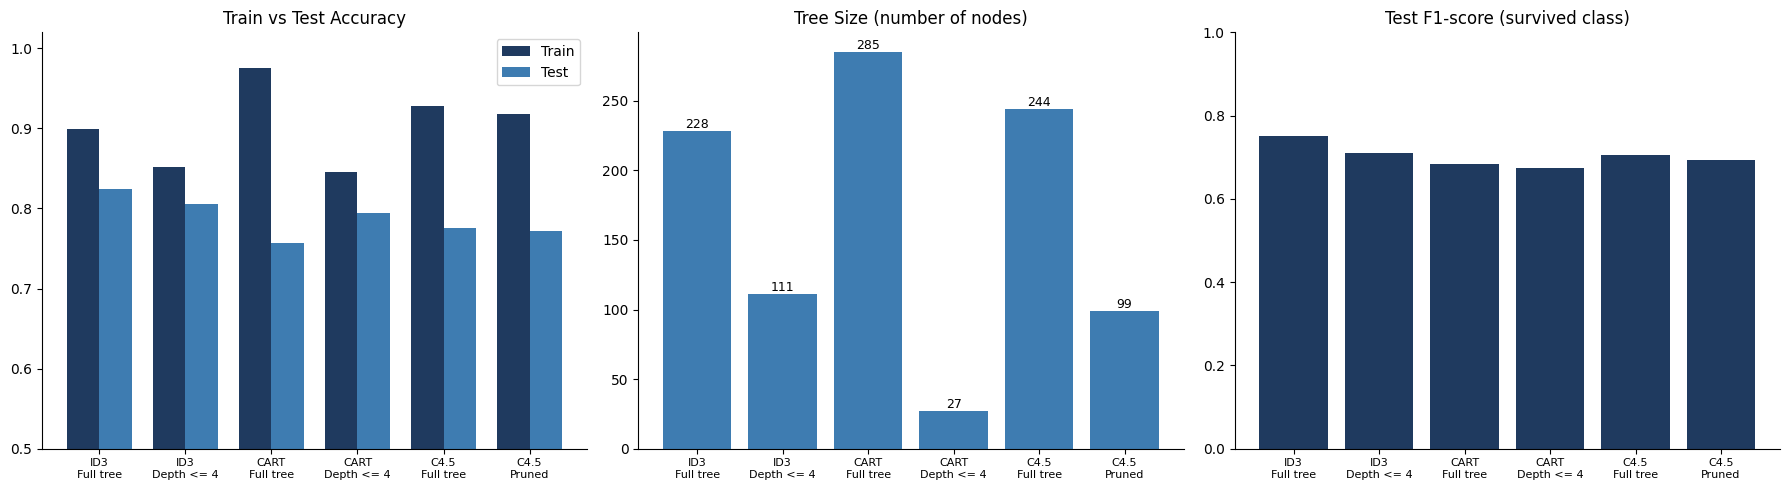

In [12]:
res = pd.DataFrame(results)
res["Label"] = res["Algorithm"] + "\n" + res["Setting"].str.replace(" (no pruning)", "").str.replace("After pruning", "Pruned")
print(res.drop(columns="Label").round(4).to_string(index=False))

navy, blue, light = "#1F3A5F", "#3E7CB1", "#A9C7E8"
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
x = np.arange(len(res)); w = 0.38

ax[0].bar(x - w / 2, res["Train Acc"], w, label="Train", color=navy)
ax[0].bar(x + w / 2, res["Test Acc"], w, label="Test", color=blue)
ax[0].set_title("Train vs Test Accuracy"); ax[0].set_ylim(0.5, 1.02); ax[0].legend()

ax[1].bar(x, res["Nodes"], color=blue)
ax[1].set_title("Tree Size (number of nodes)")
for i, v in enumerate(res["Nodes"]):
    ax[1].text(i, v, str(v), ha="center", va="bottom", fontsize=9)

ax[2].bar(x, res["F1"], color=navy)
ax[2].set_title("Test F1-score (survived class)"); ax[2].set_ylim(0, 1)

for a in ax:
    a.set_xticks(x); a.set_xticklabels(res["Label"], fontsize=8)
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## Robustness check: 10 different random splits
One 70/30 split has only 268 test passengers, so a gap of 2-4 percentage points can be pure luck. We repeat the whole experiment (preprocessing + training + testing) on 10 random splits and report mean ± std.

                 Mean Test Acc     Std
ID3 (full)              0.8190  0.0169
CART (full)             0.7892  0.0213
CART (depth<=4)         0.8187  0.0193
C4.5 (full)             0.7974  0.0140
C4.5 (pruned)           0.8272  0.0134


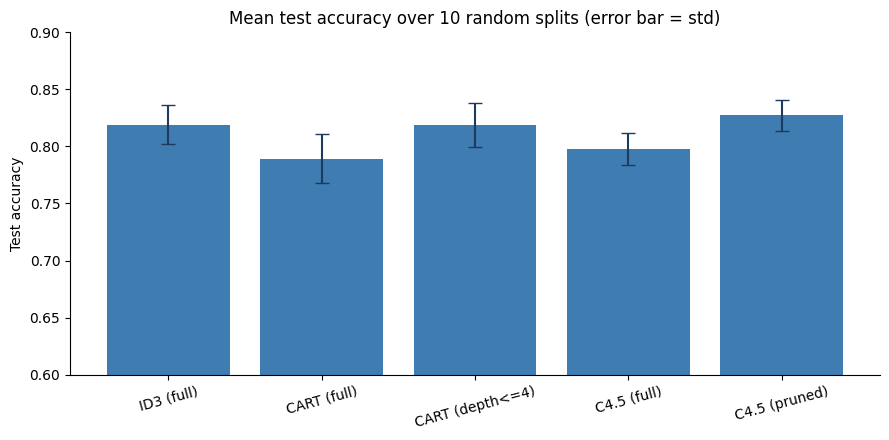

In [13]:
import copy

def acc(node, X, yv):
    return (predict(node, X) == yv).mean()

rows = []
for seed in range(10):
    tr, te = train_test_split(np.arange(len(raw)), test_size=0.3, stratify=y, random_state=seed)
    va, vb, vc = make_views(tr)
    cut = lambda X: (X.iloc[tr].reset_index(drop=True), X.iloc[te].reset_index(drop=True))
    (a_tr, a_te), (b_tr, b_te), (c_tr, c_te) = cut(va), cut(vb), cut(vc)
    y_tr, y_te = y[tr], y[te]

    id3 = build_id3(a_tr, y_tr, list(a_tr.columns))
    cart_f = build_cart(b_tr, y_tr)
    cart_4 = build_cart(b_tr, y_tr, max_depth=4)
    c45_f = build_c45(c_tr, y_tr)
    c45_p = copy.deepcopy(c45_f); prune_c45(c45_p)
    rows.append({"ID3 (full)": acc(id3, a_te, y_te),
                 "CART (full)": acc(cart_f, b_te, y_te), "CART (depth<=4)": acc(cart_4, b_te, y_te),
                 "C4.5 (full)": acc(c45_f, c_te, y_te), "C4.5 (pruned)": acc(c45_p, c_te, y_te)})

rob = pd.DataFrame(rows)
summary = pd.DataFrame({"Mean Test Acc": rob.mean(), "Std": rob.std()}).round(4)
print(summary.to_string())

plt.figure(figsize=(9, 4.5))
plt.bar(summary.index, summary["Mean Test Acc"], yerr=summary["Std"], color="#3E7CB1", ecolor="#1F3A5F", capsize=5)
plt.ylim(0.6, 0.9); plt.ylabel("Test accuracy"); plt.title("Mean test accuracy over 10 random splits (error bar = std)")
plt.xticks(rotation=15); plt.gca().spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## Cross-check with scikit-learn
`scikit-learn` implements an optimised **CART**. Using `criterion="entropy"` swaps the Gini index for information gain, which is only *similar in spirit* to ID3 / C4.5 (it still makes binary splits and has no gain ratio).

sklearn criterion   max_depth  Train Acc  Test Acc  Nodes
             gini           4     0.8459    0.7948     27
             gini None (full)     0.9759    0.7575    289
          entropy           4     0.8459    0.7948     27
          entropy None (full)     0.9759    0.7687    293

Our scratch CART (depth <= 4): Test Acc = 0.7948


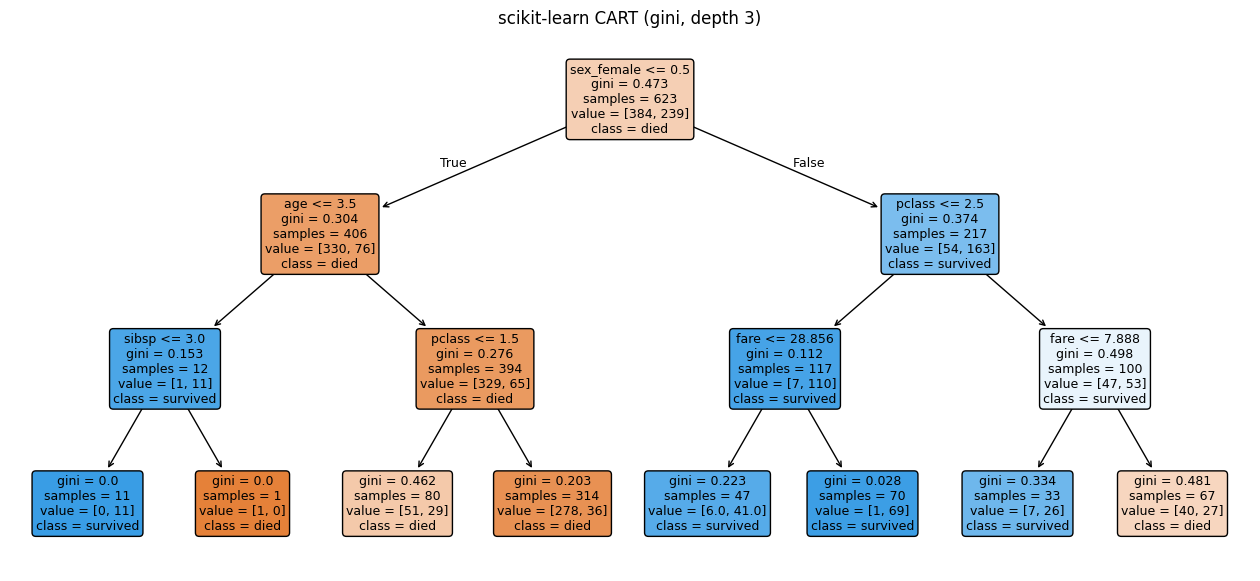

In [14]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

Xd = pd.get_dummies(X_cart, columns=["sex", "embarked"], dtype=int)
Xd_tr, Xd_te = Xd.iloc[train_idx], Xd.iloc[test_idx]

rows = []
for crit in ["gini", "entropy"]:
    for depth in [4, None]:
        clf = DecisionTreeClassifier(criterion=crit, max_depth=depth, random_state=42).fit(Xd_tr, ytr)
        rows.append({"sklearn criterion": crit, "max_depth": depth if depth else "None (full)",
                     "Train Acc": clf.score(Xd_tr, ytr), "Test Acc": clf.score(Xd_te, yte), "Nodes": clf.tree_.node_count})
print(pd.DataFrame(rows).round(4).to_string(index=False))
print("\nOur scratch CART (depth <= 4): Test Acc =", round(res.loc[(res.Algorithm == "CART") & (res.Setting == "Depth <= 4"), "Test Acc"].iloc[0], 4))

clf = DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=42).fit(Xd_tr, ytr)
plt.figure(figsize=(16, 7))
plot_tree(clf, feature_names=list(Xd.columns), class_names=["died", "survived"], filled=True, rounded=True, fontsize=9)
plt.title("scikit-learn CART (gini, depth 3)"); plt.show()

## Final Conclusion
- **Pruning matters most.** Over 10 random splits, limiting / pruning the tree raised mean test accuracy for CART from 0.789 to 0.819 and for C4.5 from 0.797 to 0.827.
- **No big winner.** C4.5 (pruned) has the best mean (0.827), but ID3 (0.819) and CART depth ≤ 4 (0.819) are within about one standard deviation. On this dataset the three algorithms perform similarly.
- **ID3 did well here** because the `unknown` age category keeps the useful fact that age was missing, and only 7 binned attributes limit its depth. CART and C4.5 lose that signal (median fill / largest-branch rule).
- **ID3's real weakness shows in the `row_id` test:** it picked the useless ID as root (train 1.00, test 0.6157 = baseline), while C4.5 picked `sex`.
- **Readability:** CART with depth ≤ 4 gives the smallest tree (27 nodes); C4.5 pruning cut 244 nodes down to 99.
- **Validation:** our scratch CART gives exactly the same result as scikit-learn (27 nodes, test accuracy 0.7948).
- **Insight:** all three trees choose `sex` first, then class / age / fare: "women and children first" is what the data shows.


## Viva Questions
| Question | Short answer |
|---|---|
| What does a decision tree do? | Repeatedly splits data on the best attribute to form if-then rules ending in class labels |
| How does ID3 choose a split? | Highest Information Gain = entropy before − weighted entropy after |
| Why can ID3 pick a useless attribute? | Many-valued attributes (like an ID) create tiny pure branches and get maximum gain |
| Why CART after ID3? | Handles numeric attributes via thresholds, uses binary splits, supports pruning, works for regression too |
| Gini vs Entropy? | Both measure impurity; Gini (1 − Σp²) is cheaper to compute, entropy uses logs; results are usually very similar |
| What is Gain Ratio? | Information Gain divided by Split Information, which punishes attributes with many values |
| How does C4.5 handle numeric data? | Tries thresholds between sorted values and picks the best one by gain |
| How does C4.5 handle missing values? | Gain is computed on known values only; fractional instances go down all branches (simplified here: largest branch) |
| What is pruning and why? | Removing branches that fit noise; reduces overfitting and gives a smaller, more general tree |
| When to stop splitting? | Node is pure, no attributes left, too few samples, or depth limit reached |